# Homework 12 — GPTQ Quantization & Knowledge Distillation

**Runtime:** Google Colab → *Runtime ▸ Change runtime type ▸ GPU* (T4 or better). Run all cells top to bottom.

| Part | What it does | Approx. time on a T4 |
|---|---|---|
| 0 | Setup, config, shared helpers | 3–5 min (installs) |
| 1 | Base LLM vs GPTQ 4‑bit on WikiText‑2: perplexity, p50/p95 latency, peak GPU memory, disk size | ~10 min |
| 2 | BERT teacher → DistilBERT student on AG News, temperature sweep (T = 1, 2, 5, 10) and α sweep (0.25, 0.5, 0.75) | ~35–45 min |
| 3 | Measurement & analysis: Tables HW11.1 / HW11.2, per‑class accuracy, failure examples, written comparison | < 1 min |

**Course references:** [Transformers GPTQ guide](https://huggingface.co/docs/transformers/quantization/gptq) · [Salesforce/wikitext](https://huggingface.co/datasets/Salesforce/wikitext) (`wikitext-2-raw-v1`, calibration + evaluation only) · [distilbert/distilbert-base-uncased](https://huggingface.co/distilbert/distilbert-base-uncased) (student).

> **Before running:** in the **Configuration** cell, set `SEED` to your assigned seed (Assignment 1 step 0) and `BASE_MODEL_ID` to the instructor‑provided/approved LLM. Then use *Runtime ▸ Run all*.
>
> The instructor's `teacher_model` is fetched automatically from the course Google Drive folder in Part 0. If the folder is not public, Colab will ask you to **connect Google Drive**: allow it with the SJSU account that can open the folder. First add the folder to *My Drive* (open the link ▸ right‑click the folder ▸ *Organize ▸ Add shortcut ▸ My Drive*).

## Part 0 — Setup

In [1]:
# ============================ Install ============================
# Colab ships torch / torchvision / torchaudio built for the same CUDA version. If pip upgrades torch (gptqmodel
# can pull a newer one), torchaudio/torchvision no longer match and `import transformers` fails with
# "PyTorch and TorchAudio were compiled with different CUDA versions". So we
#   (1) pin Colab's preinstalled torch build while installing, and
#   (2) remove torchaudio / torchvision if they still don't load (this notebook does not use either).
# This cell never imports torch itself, so no runtime restart is needed afterwards.
import subprocess, sys

def sh(args, show=True):
    r = subprocess.run(args, capture_output=True, text=True)
    if show and r.returncode != 0: print((r.stdout + r.stderr)[-2000:])
    return r.returncode == 0

def pip(*args): return sh([sys.executable, "-m", "pip", "install", "-q", *args])

PIN_SCRIPT = ("import importlib.metadata as m\n"
              "for p in ['torch','torchvision','torchaudio']:\n"
              "    try: print(p + '==' + m.version(p).split('+')[0])\n"
              "    except Exception: pass")
pins = subprocess.run([sys.executable, "-c", PIN_SCRIPT], capture_output=True, text=True).stdout
open("/content/constraints.txt", "w").write(pins)
print("Keeping preinstalled:", pins.split())

pip("-U", "transformers", "accelerate", "datasets", "optimum>=1.24.0", "huggingface_hub", "gdown", "bottleneck",
    "-c", "/content/constraints.txt")
print("Installing gptqmodel (can take a few minutes) ...")
if not pip("-U", "gptqmodel>=1.4.3", "--no-build-isolation", "-c", "/content/constraints.txt"):
    print("gptqmodel needs a different torch -> installing without the pin and repairing below")
    pip("-U", "gptqmodel>=1.4.3", "--no-build-isolation")

# torchaudio is not used here and is the package that breaks `import transformers` -> always remove it
sh([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchaudio"], show=False)
if not sh([sys.executable, "-c", "import torchvision"], show=False):   # same CUDA check exists in torchvision
    print("torchvision does not match the installed torch -> uninstalling it (not used here)")
    sh([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision"])

chk = subprocess.run([sys.executable, "-c",
    "import torch, transformers, gptqmodel\n"
    "from transformers import AutoModelForCausalLM, GPTQConfig, get_linear_schedule_with_warmup\n"
    "print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| transformers', transformers.__version__,"
    " '| gptqmodel', gptqmodel.__version__, '| GPU ok:', torch.cuda.is_available())"], capture_output=True, text=True)
print(chk.stdout or chk.stderr[-3000:])
ok = chk.returncode == 0
assert ok, "Install check failed -- see the message above."
print("Environment OK")

Keeping preinstalled: ['torch==2.14.1', 'torchvision==0.29.1', 'torchaudio==2.11.0']
Installing gptqmodel (can take a few minutes) ...


INFO  LogBar: headless/CI mode; progress animations disabled.                   

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.

INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           

INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.10.0 Transformers : 5.2

In [2]:
# ============================ Configuration ============================
SEED = 1605                                # SID4 -- standing course rule (Assignment 1, step 0)

# ---- Part 1 (GPTQ) ----
BASE_MODEL_ID       = "Qwen/Qwen3-0.6B"    # model used in the course-linked HF GPTQ guide (fallback: "facebook/opt-125m")
BASE_MODEL_REVISION = "main"               # resolved to an exact commit SHA below and recorded
GPTQ_BITS, GPTQ_GROUP_SIZE = 4, 128
N_CALIB_SAMPLES     = 128                  # WikiText-2 *train* split, calibration only
PPL_CTX, PPL_STRIDE = 1024, 512            # sliding-window perplexity on WikiText-2 *test*
LAT_PROMPT          = "The history of natural language processing began in the 1950s, when"
LAT_NEW_TOKENS, LAT_WARMUP, LAT_RUNS = 64, 3, 30

# ---- Part 2 (Distillation) ----
TEACHER_DRIVE_URL = "https://drive.google.com/drive/folders/1np95H5st8KiTK2mk7r5gcC-2mcKbJjbb"  # instructor's teacher_model
TEACHER_DIR  = "/content/teacher_model"    # filled in automatically by the "Get teacher_model" cell
STUDENT_ID   = "distilbert/distilbert-base-uncased"
MAX_LEN      = 128
VAL_SIZE     = 5000                        # held out from AG News train for choosing T and alpha
EPOCHS       = 1                           # identical for every run (raise to 2 if you have time)
BATCH_SIZE   = 32
LR           = 5e-5
WARMUP_FRAC  = 0.06
TEMPERATURES = [1, 2, 5, 10]               # fixed by the assignment -- HP_ID does NOT add another one
ALPHA_SWEEP  = 0.5                         # alpha used during the temperature sweep
ALPHAS       = [0.25, 0.5, 0.75]           # loss-weighting sweep at the best T
SCALE_KD_BY_T2 = True                      # Hinton et al.: multiply KL by T^2 so gradients keep scale
CLS_LAT_SAMPLES = 500                      # batch-size-1 latency samples for classifiers

OUT_DIR = "/content/hw12_outputs"

In [3]:
# --- Safety guard: a torchaudio built for another CUDA version breaks `import transformers` ---
import importlib.util, subprocess, sys
if importlib.util.find_spec("torchaudio") is not None:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchaudio"])
    print("Removed torchaudio (not needed for this homework).")
    if "transformers" in sys.modules or "torch" in sys.modules:
        raise SystemExit("torchaudio was already loaded in this session.  Do: Runtime > Restart session, "
                         "then Runtime > Run all.  (No need to delete the runtime; installs are kept.)")

import os, gc, json, time, random, math, shutil, platform
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import transformers
from transformers import (AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification,
                          GPTQConfig, get_linear_schedule_with_warmup)
from datasets import load_dataset

if not torch.cuda.is_available():
    _smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True) if shutil.which("nvidia-smi") else None
    if _smi is None or _smi.returncode != 0:
        raise SystemExit("NO GPU ATTACHED. Runtime > Change runtime type > T4 GPU > Save, then Runtime > Run all. "
                         "If Colab says GPUs are unavailable, your free GPU quota is used up -- wait a few hours "
                         "or use another Google account / Colab Pro.")
    raise SystemExit(f"A GPU is attached but torch {torch.__version__} (CUDA {torch.version.cuda}) cannot use it -- "
                     "torch was upgraded to a build the driver does not support. Do Runtime > Disconnect and delete "
                     "runtime, then Runtime > Run all (the install cell keeps Colab's own torch).\n" + _smi.stdout[:600])
DEVICE = torch.device("cuda")
OUT = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)
RESULTS = {}

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)

def free_gpu():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.synchronize()

def reset_peak():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def peak_gb():
    return torch.cuda.max_memory_allocated() / 1024**3

def dir_size_mb(path, weights_only=True):
    exts = (".safetensors", ".bin", ".pt", ".pth")
    files = [p for p in Path(path).rglob("*") if p.is_file() and (not weights_only or p.suffix in exts)]
    return sum(p.stat().st_size for p in files) / 1024**2

def pct(times):
    return float(np.percentile(times, 50)), float(np.percentile(times, 95))

set_seed()
HW = {"gpu": torch.cuda.get_device_name(0), "torch": torch.__version__,
      "transformers": transformers.__version__, "python": platform.python_version()}
print(HW)

W1124 20:51:14.514000 833 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 20:51:14.573000 833 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


{'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'transformers': '5.24.1', 'python': '3.13.16'}


In [4]:
# ===================== Get the instructor's teacher_model =====================
# 1) already in /content (re-run)  2) direct download with gdown  3) mount Google Drive  4) upload a .zip yourself
def _find_model_dir(root, max_depth=4):
    root = Path(root)
    if not root.exists(): return None
    hits = []
    for depth in range(max_depth + 1):
        for cfg in root.glob("/".join(["*"] * depth + ["config.json"])):
            d = cfg.parent
            if any(d.glob("*.safetensors")) or any(d.glob("pytorch_model*.bin")):
                hits.append(d)
        if hits: break
    hits.sort(key=lambda d: ("teacher" not in str(d).lower(), len(str(d))))
    return hits[0] if hits else None

found = _find_model_dir(TEACHER_DIR, 0) or _find_model_dir("/content/teacher_download")

# ---- 2) direct download (works if the folder is shared "Anyone with the link") ----
if found is None:
    import gdown
    try:
        try:
            gdown.download_folder(url=TEACHER_DRIVE_URL, output="/content/teacher_download", quiet=False, remaining_ok=True)
        except TypeError:                                   # older gdown has no remaining_ok
            gdown.download_folder(url=TEACHER_DRIVE_URL, output="/content/teacher_download", quiet=False)
    except Exception as e:
        print("gdown could not download the folder (probably not shared publicly):", repr(e)[:300])
    found = _find_model_dir("/content/teacher_download")

# ---- 3) Google Drive (needs: folder added to My Drive + approve ALL permissions in the pop-up) ----
if found is None:
    print("\nTrying Google Drive. In the pop-up pick the account that can open the folder and tick every permission box.")
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        for root in ["/content/drive/MyDrive/teacher_model", "/content/drive/MyDrive",
                     "/content/drive/Shareddrives", "/content/drive/.shortcut-targets-by-id"]:
            found = _find_model_dir(root, 3 if root.endswith("teacher_model") else 4)
            if found: break
    except Exception as e:
        print("Google Drive mount failed:", repr(e)[:300])

# ---- 4) manual upload: download the folder as .zip on your computer, then choose it here ----
if found is None:
    print("\nUpload the teacher_model .zip  (Drive link -> right-click the folder -> Download).")
    print("Drive may split a large folder into several zips -- select ALL of them in the file picker.")
    from google.colab import files
    import zipfile
    up_dir = Path("/content/teacher_download"); up_dir.mkdir(parents=True, exist_ok=True)
    for name, data in files.upload().items():
        dest = up_dir / name
        dest.write_bytes(data)
        if zipfile.is_zipfile(dest):
            zipfile.ZipFile(dest).extractall(up_dir); dest.unlink()
    found = _find_model_dir(up_dir)

assert found is not None, "teacher_model not found -- see the options printed above and re-run this cell."
if not str(found).startswith("/content/teacher_model"):    # copy to local disk: faster and stable
    shutil.copytree(found, "/content/teacher_model", dirs_exist_ok=True); found = Path("/content/teacher_model")
TEACHER_DIR = str(found)
print("TEACHER_DIR =", TEACHER_DIR)
for f in sorted(Path(TEACHER_DIR).iterdir()): print(f"  {f.name:35s} {f.stat().st_size/1024**2:8.1f} MB")

Retrieving folder contents


gdown could not download the folder (probably not shared publicly): DownloadError("Failed to retrieve folder contents for folder ID: 1np95H5st8KiTK2mk7r5gcC-2mcKbJjbb (status code 401). You may need to change the permission to 'Anyone with the link', or have had many accesses. Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.")

Trying Google Drive. In the pop-up pick the account that can open the folder and tick every permission box.
Mounted at /content/drive

Upload the teacher_model .zip  (Drive link -> right-click the folder -> Download).
Drive may split a large folder into several zips -- select ALL of them in the file picker.


Saving teacher_model-20261124T071721Z-1-001.zip to teacher_model-20261124T071721Z-1-001.zip
TEACHER_DIR = /content/teacher_model
  __MACOSX                                 0.0 MB
  config.json                              0.0 MB
  model.safetensors                      417.7 MB
  special_tokens_map.json                  0.0 MB
  tokenizer.json                           0.7 MB
  tokenizer_config.json                    0.0 MB
  vocab.txt                                0.2 MB


## Part 1 — LLM optimisation with GPTQ

Protocol (identical for both models, same GPU):
* **Quality metric:** perplexity on WikiText‑2 (`wikitext-2-raw-v1`) **test** split, sliding window (`PPL_CTX` tokens, stride `PPL_STRIDE`).
* **Calibration:** `N_CALIB_SAMPLES` passages from the WikiText‑2 **train** split (no test text is seen during quantization).
* **Latency:** greedy generation of exactly `LAT_NEW_TOKENS` tokens from a fixed prompt, batch size 1, `LAT_WARMUP` warm‑up runs, then `LAT_RUNS` timed runs with `cuda.synchronize()`; we report p50 and p95.
* **Peak GPU memory:** `torch.cuda.max_memory_allocated()` from model load through evaluation and latency runs (weights + activations + KV cache).
* **Size on disk:** weight files written by `save_pretrained` (base in fp16 safetensors, GPTQ in packed int4 safetensors).

In [5]:
from huggingface_hub import HfApi
BASE_SHA = HfApi().model_info(BASE_MODEL_ID, revision=BASE_MODEL_REVISION).sha
print(f"Base model: {BASE_MODEL_ID} @ revision {BASE_SHA}")   # record this exact ID/revision
RESULTS["part1_model"] = {"model_id": BASE_MODEL_ID, "revision": BASE_SHA}

tok = AutoTokenizer.from_pretrained(BASE_MODEL_ID, revision=BASE_SHA)
wt_test  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
wt_train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
TEST_IDS = tok("\n\n".join(wt_test["text"]), return_tensors="pt").input_ids
print("WikiText-2 test tokens:", TEST_IDS.shape[1])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:140: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Base model: Qwen/Qwen3-0.6B @ revision c1899de289a04d12100db370d81485cdf75e47ca


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (10 outputs left out)

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors


WikiText-2 test tokens: 299078


In [6]:
@torch.no_grad()
def wikitext_ppl(model, ctx=PPL_CTX, stride=PPL_STRIDE):
    model.eval()
    seq_len, nll_sum, n_tok, prev_end = TEST_IDS.size(1), 0.0, 0, 0
    for begin in range(0, seq_len, stride):
        end = min(begin + ctx, seq_len)
        trg_len = end - prev_end                       # only score tokens not scored before
        ids = TEST_IDS[:, begin:end].to(model.device)
        labels = ids.clone(); labels[:, :-trg_len] = -100
        loss = model(ids, labels=labels).loss.float()
        n = (labels != -100).sum().item() - labels.size(0)   # labels are shifted internally
        nll_sum += loss.item() * n; n_tok += n
        prev_end = end
        if end == seq_len: break
    return math.exp(nll_sum / n_tok), nll_sum / n_tok

@torch.no_grad()
def gen_latency(model):
    inputs = tok(LAT_PROMPT, return_tensors="pt").to(model.device)
    kw = dict(max_new_tokens=LAT_NEW_TOKENS, min_new_tokens=LAT_NEW_TOKENS, do_sample=False,
              pad_token_id=tok.pad_token_id or tok.eos_token_id)
    for _ in range(LAT_WARMUP): model.generate(**inputs, **kw)
    times = []
    for _ in range(LAT_RUNS):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        model.generate(**inputs, **kw)
        torch.cuda.synchronize(); times.append((time.perf_counter() - t0) * 1000)
    return times

def bench_llm(name, load_fn, save_dir):
    reset_peak()
    model = load_fn()
    t0 = time.perf_counter(); ppl, loss = wikitext_ppl(model); ppl_s = time.perf_counter() - t0
    times = gen_latency(model)
    p50, p95 = pct(times)
    r = {"config": name, "perplexity": ppl, "eval_loss": loss, "p50_ms": p50, "p95_ms": p95,
         "ms_per_token_p50": p50 / LAT_NEW_TOKENS, "peak_mem_gb": peak_gb(),
         "disk_mb": dir_size_mb(save_dir), "ppl_eval_s": ppl_s, "latency_ms_all": times}
    del model; free_gpu()
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items() if k != "latency_ms_all"})
    return r

In [7]:
# ---- Base (fp16) ----
BASE_DIR = OUT / "base_fp16"
if not (BASE_DIR / "config.json").exists():
    m = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, revision=BASE_SHA, dtype=torch.float16)
    m.save_pretrained(BASE_DIR, safe_serialization=True); tok.save_pretrained(BASE_DIR); del m

set_seed()
base_res = bench_llm("Base LLM (fp16)",
    lambda: AutoModelForCausalLM.from_pretrained(BASE_DIR, dtype=torch.float16, device_map="cuda"),
    BASE_DIR)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

{'config': 'Base LLM (fp16)', 'perplexity': 19.887, 'eval_loss': 2.99, 'p50_ms': 2641.155, 'p95_ms': 3333.163, 'ms_per_token_p50': 41.268, 'peak_mem_gb': 2.679, 'disk_mb': 1136.908, 'ppl_eval_s': 68.235}


In [8]:
# ---- GPTQ quantization (calibration on WikiText-2 train only) ----
Q_DIR = OUT / f"gptq_{GPTQ_BITS}bit_g{GPTQ_GROUP_SIZE}"
rng = random.Random(SEED)
calib_pool = [t.strip() for t in wt_train["text"] if len(t.strip()) > 200 and not t.strip().startswith("=")]
calib_texts = rng.sample(calib_pool, N_CALIB_SAMPLES)

if not (Q_DIR / "config.json").exists():
    set_seed(); reset_peak()
    gptq_cfg = GPTQConfig(bits=GPTQ_BITS, group_size=GPTQ_GROUP_SIZE, desc_act=False, sym=True,
                          dataset=calib_texts, tokenizer=tok)
    t0 = time.perf_counter()
    qm = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, revision=BASE_SHA, dtype=torch.float16,
                                              quantization_config=gptq_cfg, device_map="cuda")
    QUANT_TIME_S, QUANT_PEAK_GB = time.perf_counter() - t0, peak_gb()
    qm.save_pretrained(Q_DIR, safe_serialization=True); tok.save_pretrained(Q_DIR)
    del qm; free_gpu()
    RESULTS["gptq_process"] = {"quantize_seconds": QUANT_TIME_S, "quantize_peak_gb": QUANT_PEAK_GB}
    print(f"Quantized in {QUANT_TIME_S:.1f}s (peak {QUANT_PEAK_GB:.2f} GB during quantization)")

# Reload the saved quantized checkpoint so it is measured exactly like the base model.
# GPTQModel auto-picks the Marlin kernel, which needs an Ampere+ GPU (A100/L4); on a T4 (sm_75) it fails to build.
# So we pick the kernel explicitly, trying T4-compatible backends in order, and record which one was used.
from gptqmodel import BACKEND
GPTQ_BACKENDS = [b for b in ("EXLLAMA_V2", "TRITON", "TORCH") if hasattr(BACKEND, b)]
if torch.cuda.get_device_capability(0) >= (8, 0): GPTQ_BACKENDS.insert(0, "MARLIN")

def load_gptq():
    last_err = None
    for b in GPTQ_BACKENDS:
        try:
            print(f"Loading GPTQ checkpoint with backend {b} ...")
            m = AutoModelForCausalLM.from_pretrained(
                Q_DIR, dtype=torch.float16, device_map="cuda",
                quantization_config=GPTQConfig(bits=GPTQ_BITS, backend=getattr(BACKEND, b)))
            with torch.no_grad():                                   # smoke test: kernel really runs
                m(tok("Hello world", return_tensors="pt").input_ids.to("cuda"))
            RESULTS["gptq_backend"] = b; print(f"-> using backend {b}")
            if last_err is not None:          # earlier failed attempts may have raised the peak -> reload cleanly
                del m; reset_peak()
                m = AutoModelForCausalLM.from_pretrained(
                    Q_DIR, dtype=torch.float16, device_map="cuda",
                    quantization_config=GPTQConfig(bits=GPTQ_BITS, backend=getattr(BACKEND, b)))
            return m
        except Exception as e:
            last_err = e; print(f"   backend {b} failed: {repr(e)[:200]}")
            gc.collect(); torch.cuda.empty_cache()
    raise RuntimeError(f"No GPTQ kernel backend worked on this GPU: {last_err!r}")

set_seed()
q_res = bench_llm(f"GPTQ-quantized LLM ({GPTQ_BITS}-bit, g{GPTQ_GROUP_SIZE})", load_gptq, Q_DIR)
print("GPTQ kernel backend used:", RESULTS.get("gptq_backend"))


INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.10.0 Transformers : 5.24.1 Torch        : 2.14.1+cu130 Triton       : 3.8.0


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Quantizing model.layers blocks :   0%|          | 0/28 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/7 [00:00<?, ?it/s]

INFO  GPTQ block update: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/gptq_block/509937c07a6257a6`.
INFO  GPTQ block update: torch.ops JIT extension ready in 43s.                  


Quantizing layers inside the block:   0%|          | 0/7 [00:00<?, ?it/s]

... (30 outputs left out)

Quantized in 257.5s (peak 1.55 GB during quantization)
Loading GPTQ checkpoint with backend EXLLAMA_V2 ...
INFO  Kernel: selected: `ExllamaV2Linear`                                       


/usr/local/lib/python3.13/dist-packages/transformers/quantizers/auto.py:279: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.However, loading attributes (e.g. ['backend', 'max_input_length']) will be overwritten with the one you passed to `from_pretrained`. The rest will be ignored.
  warnings.warn(warning_msg)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3312: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Loading weights:   0%|          | 0/898 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 7671 objects in 0.346s                             
-> using backend EXLLAMA_V2
{'config': 'GPTQ-quantized LLM (4-bit, g128)', 'perplexity': 21.14, 'eval_loss': 3.051, 'p50_ms': 3422.294, 'p95_ms': 4186.663, 'ms_per_token_p50': 53.473, 'peak_mem_gb': 2.073, 'disk_mb': 516.266, 'ppl_eval_s': 77.573}
GPTQ kernel backend used: EXLLAMA_V2


**Table HW11.1 — GPTQ comparison on the same LLM/task.** Model `Qwen/Qwen3-0.6B` @ `c1899de289a0`, GPU Tesla T4, latency = 64 new tokens, batch 1.

,Configuration,Quality metric (WikiText-2 PPL ↓),p50 / p95 latency (ms),Peak memory (GB),Size on disk (MB)
0,Base LLM (fp16),19.89 (loss 2.9900),2641.2 / 3333.2,2.679,1136.9
1,"GPTQ-quantized LLM (4-bit, g128)",21.14 (loss 3.0512),3422.3 / 4186.7,2.073,516.3


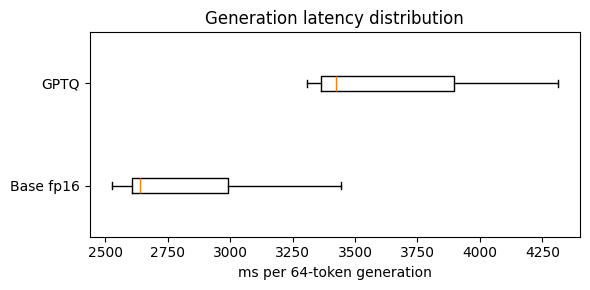


**Part 1 findings (auto-generated from the measurements above):**
* Perplexity changed from **19.89 → 21.14** (+6.3%), the accuracy cost of 4-bit weights.
* Size on disk went from **1137 MB → 516 MB** (2.20× smaller); peak GPU memory went from **2.679 → 2.073 GB**.
  Memory falls by less than disk size because activations, the KV cache and the CUDA context are not quantized, and embeddings / `lm_head` stay in fp16.
* p50 latency went from **2641.2 → 3422.3 ms** (+29.6%), p95 **3333.2 → 4186.7 ms**.
  GPTQ is weight-only quantization: weights are de-quantized on the fly inside the matmul kernel. That only pays off when decoding is memory-bandwidth-bound (large models). For small models at batch size 1, kernel-launch and de-quantization overhead can make it as fast or slower.


In [9]:
RESULTS["part1"] = [base_res, q_res]
t1 = pd.DataFrame([{
    "Configuration": r["config"],
    "Quality metric (WikiText-2 PPL ↓)": f'{r["perplexity"]:.2f}  (loss {r["eval_loss"]:.4f})',
    "p50 / p95 latency (ms)": f'{r["p50_ms"]:.1f} / {r["p95_ms"]:.1f}',
    "Peak memory (GB)": f'{r["peak_mem_gb"]:.3f}',
    "Size on disk (MB)": f'{r["disk_mb"]:.1f}'} for r in (base_res, q_res)])
display(Markdown(f"**Table HW11.1 — GPTQ comparison on the same LLM/task.** Model `{BASE_MODEL_ID}` @ `{BASE_SHA[:12]}`, "
                 f"GPU {HW['gpu']}, latency = {LAT_NEW_TOKENS} new tokens, batch 1."))
display(t1)

fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot([base_res["latency_ms_all"], q_res["latency_ms_all"]], vert=False); ax.set_yticks([1, 2], ["Base fp16", "GPTQ"])
ax.set_xlabel(f"ms per {LAT_NEW_TOKENS}-token generation"); ax.set_title("Generation latency distribution")
plt.tight_layout(); plt.show()

d = lambda a, b: (b - a) / a * 100
display(Markdown(f'''
**Part 1 findings (auto-generated from the measurements above):**
* Perplexity changed from **{base_res["perplexity"]:.2f} → {q_res["perplexity"]:.2f}** ({d(base_res["perplexity"], q_res["perplexity"]):+.1f}%), the accuracy cost of {GPTQ_BITS}-bit weights.
* Size on disk went from **{base_res["disk_mb"]:.0f} MB → {q_res["disk_mb"]:.0f} MB** ({base_res["disk_mb"]/q_res["disk_mb"]:.2f}× smaller); peak GPU memory went from **{base_res["peak_mem_gb"]:.3f} → {q_res["peak_mem_gb"]:.3f} GB**.
  Memory falls by less than disk size because activations, the KV cache and the CUDA context are not quantized, and embeddings / `lm_head` stay in fp16.
* p50 latency went from **{base_res["p50_ms"]:.1f} → {q_res["p50_ms"]:.1f} ms** ({d(base_res["p50_ms"], q_res["p50_ms"]):+.1f}%), p95 **{base_res["p95_ms"]:.1f} → {q_res["p95_ms"]:.1f} ms**.
  GPTQ is weight-only quantization: weights are de-quantized on the fly inside the matmul kernel. That only pays off when decoding is memory-bandwidth-bound (large models). For small models at batch size 1, kernel-launch and de-quantization overhead can make it as fast or slower.
'''))

## Part 2 — Knowledge distillation (BERT teacher → DistilBERT student) on AG News

The teacher was loaded into `TEACHER_DIR` by the *Get teacher_model* cell in Part 0.

**Loss:** for student logits $z_s$, teacher logits $z_t$, temperature $T$:
$$\mathcal{L} = \alpha\,\mathrm{CE}(z_s, y) + (1-\alpha)\,T^2\,\mathrm{KL}\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big)$$
$T=1$ is the no‑softening baseline. The $T^2$ factor (Hinton et al., 2015) keeps the soft‑target gradient magnitude comparable across temperatures, so α means the same thing at every $T$. At $T=1$ it is exactly $\alpha\,\mathrm{CE} + (1-\alpha)\,\mathrm{KLD}$.

**Fair‑comparison rules:** every run re‑initialises the student from the same `distilbert-base-uncased` checkpoint, calls `set_seed(SEED)`, and uses the same data order, epochs, batch size, LR and schedule. Only `T` or `α` changes. `T` and `α` are chosen on a held‑out **validation** split carved from AG News train (not on the test set). Test accuracy is reported for every run.

In [10]:
for _n in ["m", "qm", "model"]: globals().pop(_n, None)   # release anything left over from Part 1
free_gpu()

ag = load_dataset("fancyzhx/ag_news")
LABELS = ag["train"].features["label"].names            # ['World', 'Sports', 'Business', 'Sci/Tech']
NUM_LABELS = len(LABELS)
ag_train_full = ag["train"].add_column("idx", list(range(len(ag["train"]))))
ag_test = ag["test"]
split = ag_train_full.train_test_split(test_size=VAL_SIZE, seed=SEED, stratify_by_column="label")
ag_train, ag_val = split["train"], split["test"]
print(len(ag_train), "train /", len(ag_val), "val /", len(ag_test), "test;", LABELS)

# ---- Teacher (loaded locally from TEACHER_DIR) ----
assert Path(TEACHER_DIR, "config.json").exists(), f"teacher_model not found at {TEACHER_DIR}"
t_tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
print("teacher id2label:", teacher.config.id2label, "| params:", f"{teacher.num_parameters()/1e6:.1f}M")
assert teacher.config.num_labels == NUM_LABELS

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

115000 train / 5000 val / 7600 test; ['World', 'Sports', 'Business', 'Sci/Tech']


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

teacher id2label: {0: 'WORLD', 1: 'SPORTS', 2: 'BUSINESS', 3: 'SCI/TECH'} | params: 109.5M


In [11]:
@torch.no_grad()
def predict_logits(model, tokenizer, texts, bs=256, max_len=MAX_LEN):
    model.eval(); out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(**enc).logits.float().cpu())
    return torch.cat(out)

# Sanity check of label order: the teacher must agree with dataset labels on a test slice
_chk = ag_test.select(range(2000))
_acc = (predict_logits(teacher, t_tok, _chk["text"]).argmax(-1).numpy() == np.array(_chk["label"])).mean()
print(f"teacher accuracy on 2,000 test samples: {_acc:.4f}")
assert _acc > 0.8, "Label order mismatch between teacher and dataset -- check teacher.config.id2label"

# ---- Extract teacher logits for ALL AG News training samples (cached to disk) ----
LOGIT_PATH = OUT / "teacher_train_logits.pt"
if LOGIT_PATH.exists():
    TEACHER_LOGITS = torch.load(LOGIT_PATH)
else:
    t0 = time.perf_counter()
    TEACHER_LOGITS = predict_logits(teacher, t_tok, ag_train_full["text"])
    torch.save(TEACHER_LOGITS, LOGIT_PATH)
    print(f"extracted logits in {time.perf_counter()-t0:.1f}s")
print("teacher logits:", tuple(TEACHER_LOGITS.shape),
      "| teacher train acc:", (TEACHER_LOGITS.argmax(-1).numpy() == np.array(ag_train_full["label"])).mean().round(4))
del teacher; free_gpu()

teacher accuracy on 2,000 test samples: 0.9455
extracted logits in 221.8s
teacher logits: (120000, 4) | teacher train acc: 0.9895


In [12]:
s_tok = AutoTokenizer.from_pretrained(STUDENT_ID)
def tok_fn(b): return s_tok(b["text"], truncation=True, max_length=MAX_LEN)
train_tok = ag_train.map(tok_fn, batched=True, remove_columns=["text"])

def collate(batch):
    enc = s_tok.pad([{"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]} for b in batch],
                    return_tensors="pt")
    enc["labels"] = torch.tensor([b["label"] for b in batch])
    enc["idx"] = torch.tensor([b["idx"] for b in batch])
    return enc

def kd_loss(s_logits, t_logits, labels, T, alpha):
    ce = F.cross_entropy(s_logits, labels)
    kld = F.kl_div(F.log_softmax(s_logits / T, -1), F.softmax(t_logits / T, -1), reduction="batchmean")
    if SCALE_KD_BY_T2: kld = kld * T * T
    return alpha * ce + (1 - alpha) * kld, ce, kld

def train_student(T, alpha, log_every=200):
    run = f"T{T}_a{alpha}"
    save_dir = OUT / "students" / run
    set_seed(SEED)                                                     # same init + same data order
    student = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_ID, num_labels=NUM_LABELS, id2label=dict(enumerate(LABELS)),
        label2id={l: i for i, l in enumerate(LABELS)}).to(DEVICE)
    loader = torch.utils.data.DataLoader(train_tok, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate,
                                         generator=torch.Generator().manual_seed(SEED), num_workers=2)
    opt = torch.optim.AdamW(student.parameters(), lr=LR, weight_decay=0.01)
    total = len(loader) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda")
    log, acc_l, acc_ce, acc_kd, step, t0 = [], 0.0, 0.0, 0.0, 0, time.perf_counter()
    student.train()
    for ep in range(EPOCHS):
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                s_logits = student(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            t_logits = TEACHER_LOGITS[batch["idx"].cpu()].to(DEVICE)
            loss, ce, kld = kd_loss(s_logits.float(), t_logits, batch["labels"], T, alpha)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1; acc_l += loss.item(); acc_ce += ce.item(); acc_kd += kld.item()
            if step % log_every == 0 or step == total:
                n = log_every if step % log_every == 0 else step % log_every
                rec = {"run": run, "step": step, "epoch": step / len(loader), "loss": acc_l / n,
                       "ce": acc_ce / n, "kld": acc_kd / n, "lr": sched.get_last_lr()[0],
                       "elapsed_s": time.perf_counter() - t0}
                log.append(rec); acc_l = acc_ce = acc_kd = 0.0
                if step % (log_every * 5) == 0 or step == total:
                    print(f"[{run}] step {step:>5}/{total}  loss {rec['loss']:.4f}  ce {rec['ce']:.4f}  "
                          f"kld {rec['kld']:.4f}  lr {rec['lr']:.2e}  {rec['elapsed_s']:.0f}s")
    train_s = time.perf_counter() - t0
    val_pred = predict_logits(student, s_tok, ag_val["text"]).argmax(-1).numpy()
    test_pred = predict_logits(student, s_tok, ag_test["text"]).argmax(-1).numpy()
    val_acc = (val_pred == np.array(ag_val["label"])).mean()
    test_acc = (test_pred == np.array(ag_test["label"])).mean()
    student.save_pretrained(save_dir, safe_serialization=True); s_tok.save_pretrained(save_dir)
    del student, opt, scaler; free_gpu()
    print(f"[{run}] val acc {val_acc:.4f} | test acc {test_acc:.4f} | train {train_s/60:.1f} min")
    return {"run": run, "T": T, "alpha": alpha, "val_acc": float(val_acc), "test_acc": float(test_acc),
            "train_min": train_s / 60, "dir": str(save_dir), "test_pred": test_pred, "log": log}

RUNS = {}

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/115000 [00:00<?, ? examples/s]

### Measurement 2 — temperature sweep (α = 0.5, T ∈ {1, 2, 5, 10})

In [13]:
for T in TEMPERATURES:
    key = (T, ALPHA_SWEEP)
    if key not in RUNS: RUNS[key] = train_student(T, ALPHA_SWEEP)

temp_df = pd.DataFrame([{"T": T, "alpha": ALPHA_SWEEP, "val acc": RUNS[(T, ALPHA_SWEEP)]["val_acc"],
                         "test acc": RUNS[(T, ALPHA_SWEEP)]["test_acc"],
                         "train time (min)": RUNS[(T, ALPHA_SWEEP)]["train_min"]} for T in TEMPERATURES])
BEST_T = int(temp_df.loc[temp_df["val acc"].idxmax(), "T"])
display(Markdown(f"**Temperature sweep (α = {ALPHA_SWEEP}, seed {SEED}).** Best T by validation accuracy: **T = {BEST_T}**"))
display(temp_df.style.format({"val acc": "{:.4f}", "test acc": "{:.4f}", "train time (min)": "{:.1f}"})
        .highlight_max(subset=["val acc"], color="#c6efce"))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[T1_a0.5] step  1000/3594  loss 0.2106  ce 0.2269  kld 0.1943  lr 3.84e-05  98s
[T1_a0.5] step  2000/3594  loss 0.1720  ce 0.1885  kld 0.1556  lr 2.36e-05  194s
[T1_a0.5] step  3000/3594  loss 0.1566  ce 0.1742  kld 0.1390  lr 8.79e-06  291s
[T1_a0.5] step  3594/3594  loss 0.1561  ce 0.1746  kld 0.1377  lr 0.00e+00  349s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (14 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[T10_a0.5] val acc 0.9420 | test acc 0.9441 | train 5.8 min


**Temperature sweep (α = 0.5, seed 1605).** Best T by validation accuracy: **T = 5**

,T,alpha,val acc,test acc,train time (min)
0,1,0.500000,0.9412,0.9434,5.8
1,2,0.500000,0.9410,0.9434,5.9
2,5,0.500000,0.9426,0.9439,6.0
3,10,0.500000,0.9420,0.9441,5.8


### Measurement 3 — loss‑weighting sweep at the best T (α ∈ {0.25, 0.5, 0.75})

In [14]:
for a in ALPHAS:
    key = (BEST_T, a)            # alpha=0.5 at BEST_T is identical to the sweep run, so it is reused
    if key not in RUNS: RUNS[key] = train_student(BEST_T, a)

alpha_df = pd.DataFrame([{"T": BEST_T, "alpha": a, "val acc": RUNS[(BEST_T, a)]["val_acc"],
                          "test acc": RUNS[(BEST_T, a)]["test_acc"]} for a in ALPHAS])
BEST_ALPHA = float(alpha_df.loc[alpha_df["val acc"].idxmax(), "alpha"])
BEST = RUNS[(BEST_T, BEST_ALPHA)]
display(Markdown(f"**α sweep at T = {BEST_T}.** Best: **α = {BEST_ALPHA}** → student `{BEST['run']}`"))
display(alpha_df.style.format({"val acc": "{:.4f}", "test acc": "{:.4f}"}).highlight_max(subset=["val acc"], color="#c6efce"))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[T5_a0.25] step  1000/3594  loss 0.7564  ce 0.3180  kld 0.9025  lr 3.84e-05  97s
[T5_a0.25] step  2000/3594  loss 0.5667  ce 0.2564  kld 0.6701  lr 2.36e-05  193s
[T5_a0.25] step  3000/3594  loss 0.4927  ce 0.2307  kld 0.5800  lr 8.79e-06  290s
[T5_a0.25] step  3594/3594  loss 0.4965  ce 0.2418  kld 0.5813  lr 0.00e+00  348s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[T5_a0.25] val acc 0.9434 | test acc 0.9425 | train 5.8 min


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[T5_a0.75] val acc 0.9402 | test acc 0.9441 | train 5.8 min


**α sweep at T = 5.** Best: **α = 0.25** → student `T5_a0.25`

,T,alpha,val acc,test acc
0,5,0.250000,0.9434,0.9425
1,5,0.500000,0.9426,0.9439
2,5,0.750000,0.9402,0.9441


### Sample training log, summary metrics and loss trends

Sample training log -- best run T5_a0.25 (every 200 steps, running means):


,run,step,epoch,loss,ce,kld,lr,elapsed_s
72,T5_a0.25,200,0.0556,3.9737,0.7049,5.0633,0.0,19.3977
73,T5_a0.25,400,0.1113,1.1590,0.4751,1.3870,0.0,38.5933
74,T5_a0.25,600,0.1669,0.9613,0.3872,1.1527,0.0,58.0972
75,T5_a0.25,800,0.2226,0.8384,0.3424,1.0037,0.0,77.4088
76,T5_a0.25,1000,0.2782,0.7564,0.3180,0.9025,0.0,96.8105
77,T5_a0.25,1200,0.3339,0.7230,0.3076,0.8615,0.0,116.4231
78,T5_a0.25,1400,0.3895,0.6974,0.2931,0.8321,0.0,135.5359
79,T5_a0.25,1600,0.4452,0.6356,0.2709,0.7571,0.0,154.5535
80,T5_a0.25,1800,0.5008,0.6619,0.2940,0.7846,0.0,173.9996
81,T5_a0.25,2000,0.5565,0.5667,0.2564,0.6701,0.0,193.4153


**Summary metrics for all distillation runs**

,run,T,alpha,final loss,final CE,final KLD,val acc,test acc,train min
4,T5_a0.25,5,0.25,0.4965,0.2418,0.5813,0.9434,0.9425,5.8025
0,T1_a0.5,1,0.50,0.1561,0.1746,0.1377,0.9412,0.9434,5.8199
1,T2_a0.5,2,0.50,0.2834,0.2026,0.3643,0.9410,0.9434,5.8818
2,T5_a0.5,5,0.50,0.4043,0.2307,0.5779,0.9426,0.9439,5.9582
3,T10_a0.5,10,0.50,0.3990,0.2317,0.5663,0.9420,0.9441,5.8226
5,T5_a0.75,5,0.75,0.3067,0.2135,0.5863,0.9402,0.9441,5.8211


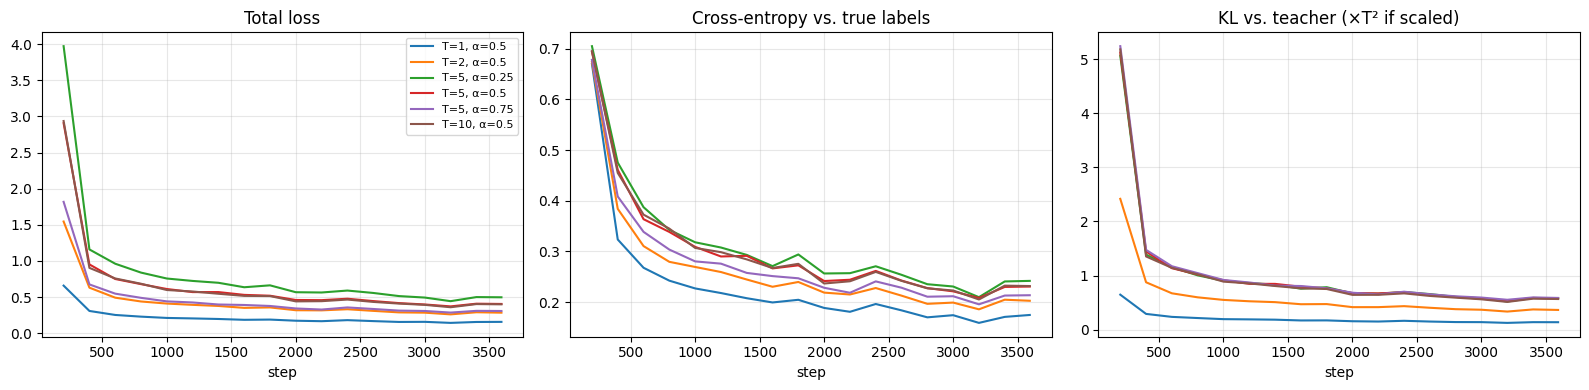

In [15]:
log_df = pd.concat([pd.DataFrame(r["log"]) for r in RUNS.values()], ignore_index=True)
log_df.to_csv(OUT / "training_logs.csv", index=False)
print(f"Sample training log -- best run {BEST['run']} (every 200 steps, running means):")
display(log_df[log_df.run == BEST["run"]].round(4).head(20))

summary = pd.DataFrame([{"run": r["run"], "T": r["T"], "alpha": r["alpha"],
                         "final loss": r["log"][-1]["loss"], "final CE": r["log"][-1]["ce"],
                         "final KLD": r["log"][-1]["kld"], "val acc": r["val_acc"], "test acc": r["test_acc"],
                         "train min": r["train_min"]} for r in RUNS.values()]).sort_values(["alpha", "T"])
display(Markdown("**Summary metrics for all distillation runs**")); display(summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (T, a), r in sorted(RUNS.items()):
    d_ = pd.DataFrame(r["log"])
    for ax, col in zip(axes, ["loss", "ce", "kld"]):
        ax.plot(d_["step"], d_[col], label=f"T={T}, α={a}")
for ax, t in zip(axes, ["Total loss", "Cross-entropy vs. true labels", "KL vs. teacher (×T² if scaled)"]):
    ax.set_title(t); ax.set_xlabel("step"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Teacher vs. best distilled student — same AG News test set, same GPU
* **Accuracy:** full 7,600‑example test set.
* **Latency:** one request at a time (batch 1), `CLS_LAT_SAMPLES` test texts, 20 warm‑up runs, fp32, `cuda.synchronize()` around each call; p50 / p95 reported. Full‑test‑set batched throughput time is reported too.
* **Peak memory:** `max_memory_allocated` from model load through the whole evaluation.
* **Size on disk:** both models re‑saved with `save_pretrained` (fp32 safetensors), so the format is identical.

In [16]:
@torch.no_grad()
def bench_classifier(name, path):
    reset_peak()
    tk = AutoTokenizer.from_pretrained(path)
    model = AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE).eval()
    n_params = model.num_parameters()
    t0 = time.perf_counter(); logits = predict_logits(model, tk, ag_test["text"]); torch.cuda.synchronize()
    batched_s = time.perf_counter() - t0
    preds = logits.argmax(-1).numpy()
    texts = ag_test.shuffle(seed=SEED).select(range(CLS_LAT_SAMPLES))["text"]
    for t in texts[:20]: model(**tk(t, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE))
    times = []
    for t in texts:
        enc = tk(t, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        torch.cuda.synchronize(); s = time.perf_counter(); model(**enc); torch.cuda.synchronize()
        times.append((time.perf_counter() - s) * 1000)
    p50, p95 = pct(times)
    save = OUT / "size_check" / name.split()[0].lower()
    model.save_pretrained(save, safe_serialization=True)
    r = {"config": name, "accuracy": float((preds == np.array(ag_test["label"])).mean()), "p50_ms": p50, "p95_ms": p95,
         "peak_mem_gb": peak_gb(), "disk_mb": dir_size_mb(save), "params_M": n_params / 1e6,
         "test_set_batched_s": batched_s, "preds": preds, "probs": logits.softmax(-1).numpy()}
    del model; free_gpu()
    return r

teach_res = bench_classifier("Teacher (BERT-base)", TEACHER_DIR)
stud_res  = bench_classifier(f"Best distilled student (DistilBERT, T={BEST_T}, α={BEST_ALPHA})", BEST["dir"])
RESULTS["part2"] = {k: {kk: vv for kk, vv in v.items() if kk not in ("preds", "probs")}
                    for k, v in {"teacher": teach_res, "student": stud_res}.items()}

t2 = pd.DataFrame([{"Configuration": r["config"], "Accuracy": f'{r["accuracy"]*100:.2f}%',
                    "p50 / p95 latency (ms)": f'{r["p50_ms"]:.2f} / {r["p95_ms"]:.2f}',
                    "Peak memory (GB)": f'{r["peak_mem_gb"]:.3f}', "Size on disk (MB)": f'{r["disk_mb"]:.1f}',
                    "Params (M)": f'{r["params_M"]:.1f}', "Full test set, batched (s)": f'{r["test_set_batched_s"]:.2f}'}
                   for r in (teach_res, stud_res)])
display(Markdown(f"**Table HW11.2 — the separate distillation comparison on AG News** (GPU {HW['gpu']}, batch‑1 latency)."))
display(t2)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

**Table HW11.2 — the separate distillation comparison on AG News** (GPU Tesla T4, batch‑1 latency).

,Configuration,Accuracy,p50 / p95 latency (ms),Peak memory (GB),Size on disk (MB),Params (M),"Full test set, batched (s)"
0,Teacher (BERT-base),94.43%,8.42 / 9.94,1.290,417.7,109.5,14.03
1,"Best distilled student (DistilBERT, T=5, α=0.25)",94.25%,4.33 / 7.09,1.001,255.4,67.0,7.53


### Measurement 4 — where the compression hurts (per‑class accuracy)

In [17]:
y = np.array(ag_test["label"])
pc = pd.DataFrame({"class": LABELS,
                   "teacher acc": [(teach_res["preds"][y == c] == c).mean() for c in range(NUM_LABELS)],
                   "student acc": [(stud_res["preds"][y == c] == c).mean() for c in range(NUM_LABELS)]})
pc["drop (pts)"] = (pc["teacher acc"] - pc["student acc"]) * 100
WORST = int(pc["drop (pts)"].idxmax())
display(pc.style.format({"teacher acc": "{:.4f}", "student acc": "{:.4f}", "drop (pts)": "{:+.2f}"})
        .highlight_max(subset=["drop (pts)"], color="#ffc7ce"))
print(f"Class that degrades most: {LABELS[WORST]}")

cm = pd.crosstab(pd.Series(y, name="true"), pd.Series(stud_res["preds"], name="student pred"))
cm.index, cm.columns = [LABELS[i] for i in cm.index], [LABELS[i] for i in cm.columns]
display(Markdown("Student confusion matrix:")); display(cm)

mask = (y == WORST) & (teach_res["preds"] == WORST) & (stud_res["preds"] != WORST)
cand = np.where(mask)[0]
print(f"{len(cand)} test examples of class '{LABELS[WORST]}' the teacher gets right and the student gets wrong")
pick = np.random.default_rng(SEED).choice(cand, size=min(5, len(cand)), replace=False)
ex = pd.DataFrame([{"test idx": int(i), "text": ag_test[int(i)]["text"],
                    "student pred": LABELS[stud_res["preds"][i]],
                    "teacher p(true)": round(float(teach_res["probs"][i, WORST]), 3),
                    "student p(true)": round(float(stud_res["probs"][i, WORST]), 3),
                    "n words": len(ag_test[int(i)]["text"].split())} for i in pick])
with pd.option_context("display.max_colwidth", None): display(ex)

# Evidence to support the "what do they have in common" answer
all_fail = pd.Series([LABELS[p] for p in stud_res["preds"][cand]]).value_counts()
print("Where the student sends ALL such failures:", all_fail.to_dict())
print(f"Mean teacher confidence on these failures: {teach_res['probs'][cand, WORST].mean():.3f} "
      f"vs. {teach_res['probs'][(y == WORST) & (teach_res['preds'] == WORST), WORST].mean():.3f} on all teacher-correct {LABELS[WORST]} examples")

,class,teacher acc,student acc,drop (pts)
0,World,0.9489,0.9547,-0.58
1,Sports,0.9884,0.9895,-0.11
2,Business,0.9137,0.9000,+1.37
3,Sci/Tech,0.9263,0.9258,+0.05


Class that degrades most: Business


Student confusion matrix:

,World,Sports,Business,Sci/Tech
World,1814,8,38,40
Sports,8,1880,7,5
Business,41,9,1710,140
Sci/Tech,33,7,101,1759


59 test examples of class 'Business' the teacher gets right and the student gets wrong


,test idx,text,student pred,teacher p(true),student p(true),n words
0,7413,"Bush Pledges Strong-Dollar Policy President Bush meets with Italian Prime Minister Silvio Berlusconi in the Oval Office of the White House, Wednesday, Dec. 15, 2004, in Washington.",World,0.992,0.495,27
1,6542,"Discovery Channel Tests Power of Licensing By rushing more than 700 products under the American Chopper brand as part of a new in-house licensing program, the cable channel is relying more heavily on licensing to market shows.",Sci/Tech,0.997,0.448,37
2,2343,"PeopleSoft Plays Defense The business software maker inks a deal with IBM, but it isn't likely to dissuade Oracle.",Sci/Tech,0.979,0.046,19
3,6067,"Aussies battle EU over cheese, champagne AP - The United States and Australia have prevailed in an interim ruling by World Trade Organisation (WTO) in a dispute over the protection given by the European Union to its regional goods such as Champagne wine and Feta cheese, trade officials said.",World,0.899,0.007,49
4,3796,"Diesels, Hybrids Fated to Wed Two leading technologies used in fuel-efficient vehicles seem destined to unite. Industry experts say joining hybrid motors with diesel engines would result in the greenest mainstream vehicles ever, and the initial tests are promising.",Sci/Tech,0.988,0.401,39


Where the student sends ALL such failures: {'Sci/Tech': 39, 'World': 16, 'Sports': 4}
Mean teacher confidence on these failures: 0.920 vs. 0.990 on all teacher-correct Business examples


**What the five examples have in common**

The class that degrades most is **Business**: student accuracy is 90.00% vs. 91.37% for the teacher (−1.37 points). On the other classes the student matches or beats the teacher (World +0.58, Sports +0.11, Sci/Tech −0.05).

All five examples the teacher gets right and the student gets wrong are **Business stories whose surface topic belongs to another class**. Two are about politics and trade: Bush's strong-dollar pledge in a meeting with Berlusconi, and the WTO ruling on EU protection of Champagne and Feta. The student labelled both **World**. Three are about companies whose product is technology or media: PeopleSoft's deal with IBM against Oracle, Discovery Channel's licensing programme, and diesel–hybrid vehicle technology. The student labelled these **Sci/Tech**. The same pattern holds for all 59 such failures: 39 went to Sci/Tech and 16 to World, matching the largest off-diagonal cell of the confusion matrix (140 Business articles predicted as Sci/Tech).

These articles name politicians, countries, software companies or engines, but their actual subject is money: currency policy, trade disputes, corporate deals and marketing. The teacher was less certain on them too (mean confidence 0.920 vs. 0.990 on its other correct Business predictions), so they sit near a class boundary. The smaller student relies on the strong topic words and misses the teacher's finer cue that the story is about the economic event. Length is not the cause, since the examples range from 19 to 49 words.

### Measurement 5 — quantization vs. distillation (written comparison)

In [18]:
b, q, t, s = base_res, q_res, teach_res, stud_res
display(Markdown(f'''
**Draft. Numbers come from this run; review and adjust the wording to match your results.**

Quantization and distillation compress a model in different ways. GPTQ keeps the same {BASE_MODEL_ID} architecture and stores its weights in {GPTQ_BITS} bits, without retraining. Distillation trains a new, smaller architecture (DistilBERT, {s["params_M"]:.0f}M vs. {t["params_M"]:.0f}M parameters) to imitate the BERT teacher.
In Part 1, GPTQ shrank the checkpoint {b["disk_mb"]/q["disk_mb"]:.1f}× ({b["disk_mb"]:.0f} → {q["disk_mb"]:.0f} MB) and peak GPU memory from {b["peak_mem_gb"]:.2f} to {q["peak_mem_gb"]:.2f} GB. Perplexity moved from {b["perplexity"]:.2f} to {q["perplexity"]:.2f}, and p50 latency moved from {b["p50_ms"]:.0f} to {q["p50_ms"]:.0f} ms. The compute still runs in fp16 after on-the-fly de-quantization, so the speed gain is limited, or even negative, at this model size and batch 1.
In Part 2, distillation cut size by {t["disk_mb"]/s["disk_mb"]:.1f}× ({t["disk_mb"]:.0f} → {s["disk_mb"]:.0f} MB) and also cut p50 latency from {t["p50_ms"]:.2f} to {s["p50_ms"]:.2f} ms ({t["p50_ms"]/s["p50_ms"]:.1f}× faster), because the student has half the transformer layers and does about half the FLOPs.
Each technique has its own cost: GPTQ needs only a few minutes of calibration, while distillation needed a teacher-labelled dataset and {sum(r["train_min"] for r in RUNS.values()):.0f} GPU-minutes of training across the sweeps.
For a **latency-bound** deployment I would try **distillation first**, since fewer layers directly remove sequential compute. For a **memory-bound** deployment I would try **GPTQ first**, since it gives the largest weight-memory reduction without retraining. The two also stack: a distilled student can be quantized afterwards.
'''))


**Draft. Numbers come from this run; review and adjust the wording to match your results.**

Quantization and distillation compress a model in different ways. GPTQ keeps the same Qwen/Qwen3-0.6B architecture and stores its weights in 4 bits, without retraining. Distillation trains a new, smaller architecture (DistilBERT, 67M vs. 109M parameters) to imitate the BERT teacher.
In Part 1, GPTQ shrank the checkpoint 2.2× (1137 → 516 MB) and peak GPU memory from 2.68 to 2.07 GB. Perplexity moved from 19.89 to 21.14, and p50 latency moved from 2641 to 3422 ms. The compute still runs in fp16 after on-the-fly de-quantization, so the speed gain is limited, or even negative, at this model size and batch 1.
In Part 2, distillation cut size by 1.6× (418 → 255 MB) and also cut p50 latency from 8.42 to 4.33 ms (1.9× faster), because the student has half the transformer layers and does about half the FLOPs.
Each technique has its own cost: GPTQ needs only a few minutes of calibration, while distillation needed a teacher-labelled dataset and 35 GPU-minutes of training across the sweeps.
For a **latency-bound** deployment I would try **distillation first**, since fewer layers directly remove sequential compute. For a **memory-bound** deployment I would try **GPTQ first**, since it gives the largest weight-memory reduction without retraining. The two also stack: a distilled student can be quantized afterwards.


In [19]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items() if k not in ("preds", "probs", "test_pred", "log")}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
RESULTS.update({"hardware": HW, "seed": SEED, "best_T": BEST_T, "best_alpha": BEST_ALPHA,
                "temperature_sweep": temp_df.to_dict("records"), "alpha_sweep": alpha_df.to_dict("records"),
                "per_class": pc.to_dict("records")})
json.dump(_clean(RESULTS), open(OUT / "results.json", "w"), indent=2)
print("Saved", OUT / "results.json", "and", OUT / "training_logs.csv")

Saved /content/hw12_outputs/results.json and /content/hw12_outputs/training_logs.csv
